In [1]:
import numpy as np

def softmax(x, axis=-1):
    """Numerically stable softmax."""
    e_x = np.exp(x - np.max(x, axis=axis, keepdims=True))
    return e_x / e_x.sum(axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    """Compute scaled dot-product attention."""
    d_k = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)
    weights = softmax(scores)
    output = weights @ V
    return output, weights

# Simulate a 3-word sequence with d_k = 4 dimensional Q, K, V vectors
np.random.seed(42)
d_k = 4
words = ["The", "cat", "sleeps"]

Q = np.random.randn(3, d_k)
K = np.random.randn(3, d_k)
V = np.random.randn(3, d_k)

output, attention_weights = scaled_dot_product_attention(Q, K, V)

print("Attention Weight Matrix (each row sums to 1.0):")
print(f"{'':12s} {'Key: The':>12s} {'Key: cat':>12s} {'Key: sleeps':>12s}")
for i, word in enumerate(words):
    row = " ".join([f"{w:12.4f}" for w in attention_weights[i]])
    print(f"Query: {word:<6s} {row}")

print(f"\nRow sums (should all be 1.0): {attention_weights.sum(axis=-1)}")
print(f"Output shape: {output.shape}")

Attention Weight Matrix (each row sums to 1.0):
                 Key: The     Key: cat  Key: sleeps
Query: The          0.3929       0.1682       0.4390
Query: cat          0.2309       0.2834       0.4857
Query: sleeps       0.2255       0.5587       0.2158

Row sums (should all be 1.0): [1. 1. 1.]
Output shape: (3, 4)


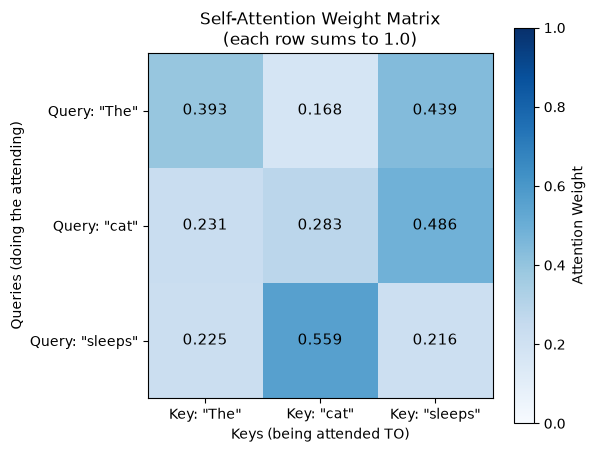


What does this tell us?
  Highest attention: 'sleeps' attends most strongly to 'cat' (0.559)


In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(attention_weights, cmap='Blues', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label='Attention Weight')

ax.set_xticks(range(len(words)))
ax.set_yticks(range(len(words)))
ax.set_xticklabels([f'Key: "{w}"' for w in words])
ax.set_yticklabels([f'Query: "{w}"' for w in words])
ax.set_title("Self-Attention Weight Matrix\n(each row sums to 1.0)")
ax.set_xlabel("Keys (being attended TO)")
ax.set_ylabel("Queries (doing the attending)")

# Annotate each cell with its value
for i in range(len(words)):
    for j in range(len(words)):
        ax.text(j, i, f"{attention_weights[i, j]:.3f}",
                ha='center', va='center', color='black', fontsize=11)

plt.tight_layout()
plt.show()

print("\nWhat does this tell us?")
max_pair = np.unravel_index(attention_weights.argmax(), attention_weights.shape)
print(f"  Highest attention: '{words[max_pair[0]]}' attends most strongly to '{words[max_pair[1]]}' ({attention_weights[max_pair]:.3f})")

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def build_attention_classifier(seq_len, d_model, num_heads, d_proj=None):
    """
    Binary sentiment classifier using self-attention.
    
    Args:
        seq_len   : maximum sequence length (number of tokens)
        d_model   : input embedding dimension (250 for Wiki-words)
        num_heads : number of parallel attention heads
        d_proj    : if set, projects embeddings to this dimension before attention
    """
    inputs = layers.Input(shape=(seq_len, d_model), name="word_embeddings")
    x = inputs

    # Optional projection: compress large embeddings to a smaller d_model
    if d_proj is not None:
        x = layers.Dense(d_proj, use_bias=False, name="input_projection")(x)
        key_dim = d_proj // num_heads
    else:
        key_dim = d_model // num_heads

    # Self-attention: every word attends to every other word simultaneously
    x = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        name="self_attention"
    )(x, x)

    # Collapse the sequence dimension — identical role to the LSTM's final hidden state
    x = layers.GlobalAveragePooling1D(name="sequence_avg")(x)

    # Binary classification output
    outputs = layers.Dense(1, activation='sigmoid', name="sentiment_output")(x)

    return Model(inputs=inputs, outputs=outputs, name="Attention_Classifier")


# Full-size model — matches the Wiki-words embedding dimension from Course 2
SEQ_LEN  = 59   # max token length from Course 2's Sentiment Dataset
D_MODEL  = 250  # Wiki-words embedding dimension
NUM_HEADS = 2

full_model = build_attention_classifier(SEQ_LEN, D_MODEL, NUM_HEADS)
print("=== Full-Size Attention Classifier ===")
full_model.summary()

=== Full-Size Attention Classifier ===


Model: "Attention_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ word_embeddings     │ (None, 59, 250)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention      │ (None, 59, 250)   │    251,000 │ word_embeddings[… │
│ (MultiHeadAttentio… │                   │            │ word_embeddings[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequence_avg        │ (None, 250)       │          0 │ self_attention[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment_output    │ (None, 1)         │        251 │ sequence_avg[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 251,251 (981.45 KB)

 Trainable params: 251,251 (981.45 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
import pandas as pd
import numpy as np
import tensorflow_hub as hub
import kagglehub
import os
import kagglehub

os.environ['KAGGLE_USERNAME'] = "yernar123"
os.environ['KAGGLE_KEY'] = "KGAT_048b45510aed7b3a4017019c504075e0"

# 1. Load the Sentiment Dataset — same source as Course 2
dataset_path = kagglehub.dataset_download("sadamumer/sentiment-dataset-positive-and-negative-texts-data")
positive_file = os.path.join(dataset_path, 'positive.txt')
negative_file = os.path.join(dataset_path, 'negative.txt')

with open(positive_file, "r", encoding="latin-1") as f:
    positives = [line.strip() for line in f]
with open(negative_file, "r", encoding="latin-1") as f:
    negatives = [line.strip() for line in f]

df = pd.DataFrame({
    'text':  positives + negatives,
    'label': [1] * len(positives) + [0] * len(negatives)
})
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# 2. Load the Wiki-words embedding model — same as Course 2
model_path = kagglehub.model_download("google/wiki-words/tensorFlow2/250")
embed = hub.load(model_path)

# 3. Preprocessing helpers (identical to Course 2)
def get_max_length(df):
    return max(len(row.split()) for row in df['text'])

def get_word2vec_enc(texts):
    return [embed(text.split()) for text in texts]

def get_padded_encoded_texts(encoded_texts, max_len):
    padded = []
    pad = np.zeros((1, 250))
    for enc in encoded_texts:
        n_pad = max_len - enc.shape[0]
        for _ in range(n_pad):
            enc = np.concatenate((pad, enc), axis=0)
        padded.append(enc)
    return padded

def preprocess(df, max_len):
    encoded = get_word2vec_enc(df['text'].tolist())
    padded  = get_padded_encoded_texts(encoded, max_len)
    return np.array(padded), np.array(df['label'].tolist())

# 4. Use only the first 200 samples for the tiny illustration
df_tiny = df.head(200).reset_index(drop=True)
max_len  = get_max_length(df)   # keep same max_len as full dataset for shape consistency
print(f"Max sequence length: {max_len}")

X_tiny, Y_tiny = preprocess(df_tiny, max_len)
print(f"Tiny X shape: {X_tiny.shape}  — (samples, seq_len, embed_dim)")
print(f"Tiny Y shape: {Y_tiny.shape}")

KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.